In [66]:
from datetime import date, timedelta
from pathlib import Path
from tempfile import TemporaryDirectory
import zipfile

import numpy as np
import pandas as pd
import rasterio

VARIABLES = ("tmin", "tmean", "tmax")

PRISM_DIR = Path("../data/prism")
NORMALS_DIR = PRISM_DIR / "normals"
NORMALS_PATH = PRISM_DIR / Path("prism_normals.parquet")


def read_normal(variable: str, month: int, day: int):
    path = next(
        (NORMALS_DIR / variable).glob(
            f"*2020{month:02d}{day:02d}_avg_30y.zip"
        )
    )

    with TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)

        with zipfile.ZipFile(path) as archive:
            archive.extractall(tmpdir)

        raster_path = next(
            p
            for p in tmpdir.rglob("*")
            if p.suffix.lower() in {".bil", ".tif", ".tiff"}
        )

        with rasterio.open(raster_path) as src:
            array = src.read(1, masked=True)

            signature = (
                src.height,
                src.width,
                tuple(src.transform),
            )

    return array, signature


reference = None
records = []

d = date(2020, 1, 1)

while d.year == 2020:
    arrays = {}

    for variable in VARIABLES:
        arr, sig = read_normal(
            variable,
            d.month,
            d.day,
        )

        if reference is None:
            reference = sig

        assert sig == reference

        arrays[variable] = arr

    height, width, _ = reference

    rows, cols = np.indices(
        (height, width),
        dtype=np.int32,
    )

    rows = rows.ravel()
    cols = cols.ravel()

    valid = np.logical_or.reduce(
        [
            ~np.ma.getmaskarray(arr).ravel()
            for arr in arrays.values()
        ]
    )

    rows = rows[valid]
    cols = cols[valid]

    records.append(
        pd.DataFrame(
            {
                "cell_id": (
                    rows.astype(np.int64) * width
                    + cols.astype(np.int64)
                ),
                "row": rows,
                "col": cols,
                "month": d.month,
                "day": d.day,
                "doy": d.timetuple().tm_yday,
                **{
                    variable: np.asarray(
                        arr.filled(np.nan).ravel()[valid],
                        dtype=np.float32,
                    )
                    for variable, arr in arrays.items()
                },
            }
        )
    )

    print(f"Processed {d:%Y-%m-%d}")

    d += timedelta(days=1)

normals = pd.concat(
    records,
    ignore_index=True,
)

normals.to_parquet(
    NORMALS_PATH,
    index=False,
)

print(f"Wrote {NORMALS_PATH}")

Processed 2020-01-01
Processed 2020-01-02
Processed 2020-01-03
Processed 2020-01-04
Processed 2020-01-05
Processed 2020-01-06
Processed 2020-01-07
Processed 2020-01-08
Processed 2020-01-09
Processed 2020-01-10
Processed 2020-01-11
Processed 2020-01-12
Processed 2020-01-13
Processed 2020-01-14
Processed 2020-01-15
Processed 2020-01-16
Processed 2020-01-17
Processed 2020-01-18
Processed 2020-01-19
Processed 2020-01-20
Processed 2020-01-21
Processed 2020-01-22
Processed 2020-01-23
Processed 2020-01-24
Processed 2020-01-25
Processed 2020-01-26
Processed 2020-01-27
Processed 2020-01-28
Processed 2020-01-29
Processed 2020-01-30
Processed 2020-01-31
Processed 2020-02-01
Processed 2020-02-02
Processed 2020-02-03
Processed 2020-02-04
Processed 2020-02-05
Processed 2020-02-06
Processed 2020-02-07
Processed 2020-02-08
Processed 2020-02-09
Processed 2020-02-10
Processed 2020-02-11
Processed 2020-02-12
Processed 2020-02-13
Processed 2020-02-14
Processed 2020-02-15
Processed 2020-02-16
Processed 202

In [67]:
normals

,cell_id,row,col,month,day,doy,tmin,tmean,tmax
0,17577,12,717,1,1,1,-20.433399,-15.273200,-10.113200
1,17578,12,718,1,1,1,-20.384399,-15.258800,-10.133400
2,17579,12,719,1,1,1,-20.307499,-15.249399,-10.191500
3,17580,12,720,1,1,1,-20.144100,-15.228100,-10.312200
4,17581,12,721,1,1,1,-20.090799,-15.200000,-10.309500
...,...,...,...,...,...,...,...,...,...
177644317,858080,610,1030,12,31,366,19.621000,21.688799,23.756599
177644318,858087,610,1037,12,31,366,19.137400,21.618599,24.099899
177644319,858088,610,1038,12,31,366,19.098099,21.612499,24.126999
177644320,858089,610,1039,12,31,366,19.107199,21.614199,24.121399


In [70]:
def open_prism_zip(zip_path: Path) -> np.ma.MaskedArray:
    with TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)

        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(tmpdir)

        raster_path = next(
            p
            for p in tmpdir.rglob("*")
            if p.suffix.lower() in {".bil", ".tif", ".tiff"}
        )

        with rasterio.open(raster_path) as src:
            return src.read(1, masked=True)

In [71]:
ROOT_DIR = Path('..')
PRISM_DIR = ROOT_DIR / "data" / "prism"

DAILY_DIR = PRISM_DIR / "daily"
NORMALS_DIR = PRISM_DIR / "normals"
MESH_DIR = PRISM_DIR / "prism_4km_mesh"
MESH_PATH = PRISM_DIR / "prism_4km_mesh" / "prism_4km_mesh.shp"

mesh = gpd.read_file(MESH_PATH)

sample = next((NORMALS_DIR / "tmean").glob("*.zip"))
arr = open_prism_zip(sample)

print("mesh cells:", len(mesh))
print("valid raster cells:", arr.count())


mesh cells: 481631
valid raster cells: 485367


In [28]:
import geopandas as gpd

prism_mesh = gpd.read_file("../data/prism/prism_4km_mesh/prism_4km_mesh.shp")
my_cells = gpd.read_parquet("../data/prism/prism_cells.parquet")

print(len(prism_mesh))
print(len(my_cells))

print(prism_mesh.crs)
print(my_cells.crs)

481631
872505
EPSG:4269
{"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "NAD83", "datum": {"type": "GeodeticReferenceFrame", "name": "North American Datum 1983", "ellipsoid": {"name": "GRS 1980", "semi_major_axis": 6378137, "inverse_flattening": 298.257222101004}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "id": {"authority": "EPSG", "code": 4269}}


<Axes: >

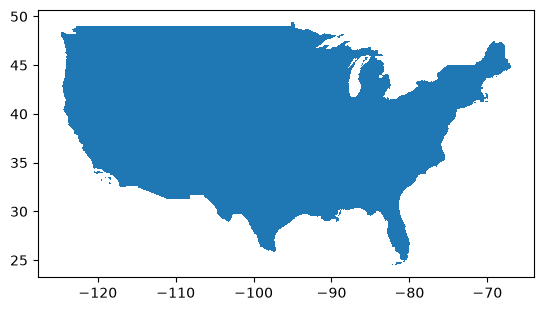

In [45]:
prism_mesh.plot()

<Axes: >

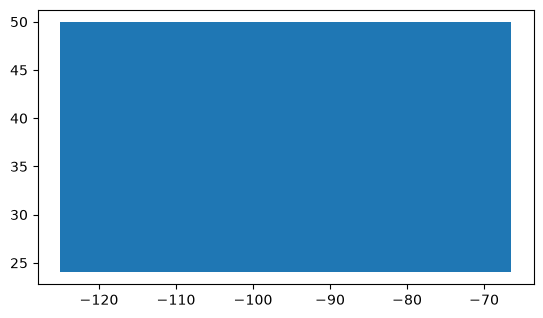

In [44]:
my_cells.plot()

<Axes: >

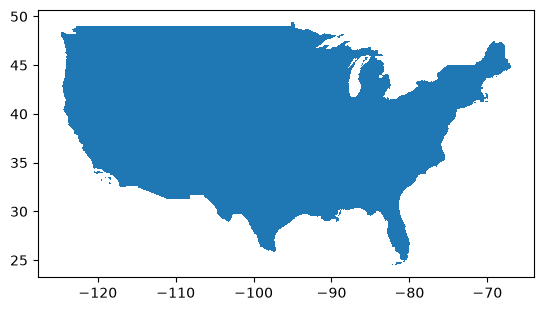

In [54]:
prism_mesh.merge(my_cells, on=["col", "row"])["geometry_y"].plot()

In [60]:
merged = prism_mesh.merge(
    my_cells,
    on=["col", "row"],
    suffixes=("_prism", "_mine"),
)


In [61]:
equal = merged.geometry_prism.geom_equals_exact(
    merged.geometry_mine,
    tolerance=1e-12,
)

assert equal.all()

AssertionError: 

In [62]:
equal = merged.geometry_prism.geom_equals_exact(
    merged.geometry_mine,
    tolerance=1e-12,
)

assert equal.all(), (
    f"{(~equal).sum()} geometries differ"
)

merged.loc[
    ~equal,
    ["row", "col", "geometry_prism", "geometry_mine"],
]

AssertionError: 481631 geometries differ

<Axes: >

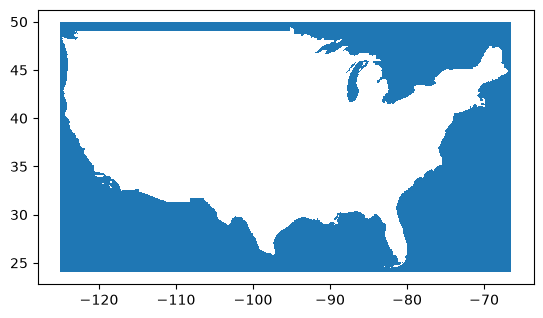

In [59]:
X = my_cells.merge(prism_mesh, on=["col", "row"], how="left")
X.set_geometry("geometry_x").loc[X["geometry_y"].isnull()].plot()

In [95]:
arr = open_prism_zip("../data/prism/normals/tmax/prism_tmax_us_25m_20200101_avg_30y.zip")

In [134]:
idxs = cells[["row", "col"]].to_numpy()
arr[*idxs.T]

masked_array(data=[-10.113200187683105, -10.035900115966797,
                   -10.103599548339844, ..., 23.69999885559082,
                   23.709400177001953, 24.05340003967285],
             mask=[False, False, False, ..., False, False, False],
       fill_value=-9999.0,
            dtype=float32)

In [135]:
mask = np.ones(arr.shape, dtype=bool)
mask[*idxs.T] = False          # knock out the cells in idxs

other_idxs = np.argwhere(mask) # (n, 2) array of (row, col) not in idxs
other_vals = arr[mask]

In [147]:
arr[*other_idxs.T][np.where(~arr[*other_idxs.T].mask)[0]]

masked_array(data=[-10.133399963378906, -10.191499710083008,
                   -10.312199592590332, ..., 24.08049964904785,
                   24.074798583984375, 24.06329917907715],
             mask=[False, False, False, ..., False, False, False],
       fill_value=-9999.0,
            dtype=float32)

In [149]:
arr.shape

(621, 1405)

In [153]:
cells["col"].nunique()

1389

In [ ]:
def open_prism_zip(zip_path: Path) -> np.ma.MaskedArray:
    with TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)

        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(tmpdir)

        raster_path = next(
            p
            for p in tmpdir.rglob("*")
            if p.suffix.lower() in {".bil", ".tif", ".tiff"}
        )

        with rasterio.open(raster_path) as src:
            return src.read(1, masked=True)

In [244]:
cells = gpd.read_file("../data/prism/prism_4km_mesh/prism_4km_mesh.shp")
filename = 'prism_tmax_us_25m_20200101_avg_30y'
zip_path = f"../data/prism/normals/tmax/{filename}.zip"
with TemporaryDirectory() as tmpdir:
    tmpdir = Path(tmpdir)

    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(tmpdir)

    raster_path = tmpdir / f"{filename}.tif"

    with rasterio.open(raster_path) as src:
        lol = src.read(1, masked=True)

(-16010, 3288)


In [205]:
rows, cols = np.indices(lol.shape)

df = pd.DataFrame({
    "row": rows.ravel(),
    "col": cols.ravel(),
    "val": lol.filled(np.nan).ravel(),
}).dropna(subset=["val"]).reset_index(drop=True)
df

,row,col,val
0,12,717,-10.113200
1,12,718,-10.133400
2,12,719,-10.191500
3,12,720,-10.312200
4,12,721,-10.309500
...,...,...,...
485362,610,1030,23.712399
485363,610,1037,24.053400
485364,610,1038,24.080500
485365,610,1039,24.074799


In [243]:
cells

,col,row,lon,lat,geometry
0,717,12,-95.125000,49.416667,"POLYGON ((-95.14583 49.4375, -95.10417 49.4375..."
1,716,13,-95.166667,49.375000,"POLYGON ((-95.1875 49.39583, -95.14583 49.3958..."
2,717,13,-95.125000,49.375000,"POLYGON ((-95.14583 49.39583, -95.10417 49.395..."
3,718,13,-95.083333,49.375000,"POLYGON ((-95.10417 49.39583, -95.0625 49.3958..."
4,719,13,-95.041667,49.375000,"POLYGON ((-95.0625 49.39583, -95.02083 49.3958..."
...,...,...,...,...,...
481626,1040,609,-81.666667,24.541667,"POLYGON ((-81.6875 24.5625, -81.64583 24.5625,..."
481627,1041,609,-81.625000,24.541667,"POLYGON ((-81.64583 24.5625, -81.60417 24.5625..."
481628,1028,610,-82.166667,24.500000,"POLYGON ((-82.1875 24.52083, -82.14583 24.5208..."
481629,1029,610,-82.125000,24.500000,"POLYGON ((-82.14583 24.52083, -82.10417 24.520..."


In [252]:
X = df.merge(cells, on=["row", "col"], how="left")
X[X.lon.isna()]

,row,col,val,lon,lat,geometry
1,12,718,-10.133400,NaN,NaN,None
2,12,719,-10.191500,NaN,NaN,None
3,12,720,-10.312200,NaN,NaN,None
4,12,721,-10.309500,NaN,NaN,None
5,12,722,-10.246600,NaN,NaN,None
...,...,...,...,...,...,...
485359,609,1042,24.084000,NaN,NaN,None
485362,610,1030,23.712399,NaN,NaN,None
485364,610,1038,24.080500,NaN,NaN,None
485365,610,1039,24.074799,NaN,NaN,None


485367 485367
0
     row   col
min   12     5
max  610  1394
     row   col
min   12     5
max  610  1393
int64 int32
               row          col
count  3736.000000  3736.000000
mean    231.111884   725.806745
std     191.371935   406.173915
min      12.000000     5.000000
25%      61.000000   375.000000
50%     158.000000   831.000000
75%     433.250000  1042.000000
max     610.000000  1394.000000


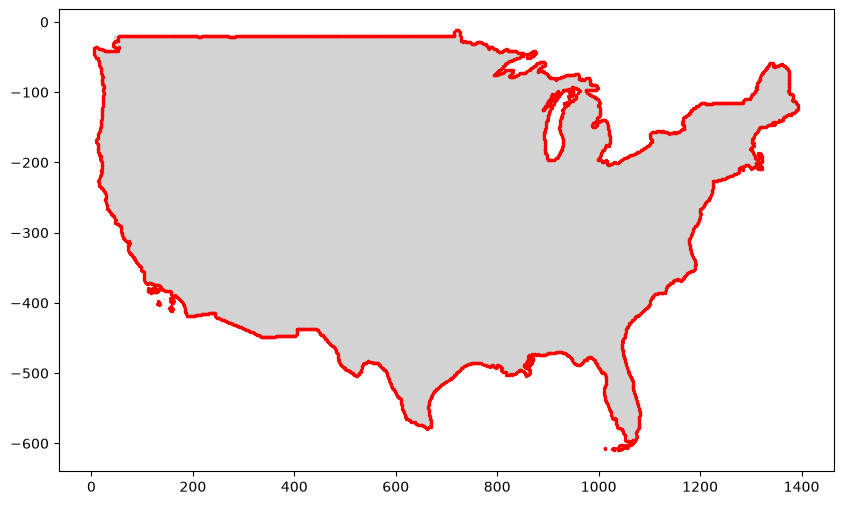

In [254]:
# 1. Make sure the merge didn't duplicate or drop rows
print(len(df), len(X))          # should be equal
print(cells.duplicated(["row", "col"]).sum())  # should be 0

# 2. Check dtypes and index ranges line up
print(df[["row", "col"]].agg(["min", "max"]))
print(cells[["row", "col"]].agg(["min", "max"]))
print(df.row.dtype, cells.row.dtype)

# 3. Where are the misses?
miss = X[X.lon.isna()]
print(miss[["row", "col"]].describe())

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df.col, -df.row, s=0.1, c="lightgray")
ax.scatter(miss.col, -miss.row, s=2, c="red")
plt.show()

<Axes: >

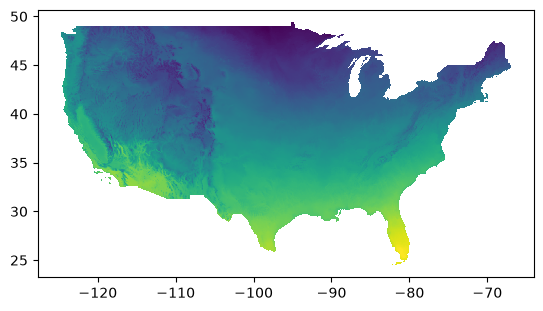

In [209]:
cells.merge(df, on=["row", "col"]).plot("val")

In [259]:
template_zip = Path(f"../data/prism/normals/tmax/{filename}.zip")
with TemporaryDirectory() as tmp:
    with zipfile.ZipFile(template_zip) as z:
        z.extractall(tmp)
    with rasterio.open(Path(tmp) / f"{template_zip.stem}.tif") as src:
        valid = ~np.ma.getmaskarray(src.read(1, masked=True))
        transform, crs = src.transform, src.crs

rows, cols = np.nonzero(valid)

# north-up grid: transform.a > 0 is the cell width, transform.e < 0 is the cell height
x0 = transform.c + transform.a * cols
y0 = transform.f + transform.e * rows
x1 = x0 + transform.a
y1 = y0 + transform.e

cells2 = gpd.GeoDataFrame(
    {
        "row": rows,
        "col": cols,
        "lon": (x0 + x1) / 2,
        "lat": (y0 + y1) / 2,
    },
    geometry=shapely.box(x0, y0, x1, y1),  # shapely 2 vectorized, no Python loop
    crs=crs,
)

In [268]:
C = cells.merge(cells2, on=["row", "col"], how="right")
C

,col,row,lon_x,lat_x,geometry_x,lon_y,lat_y,geometry_y
0,717,12,-95.125000,49.416667,"POLYGON ((-95.14583 49.4375, -95.10417 49.4375...",-95.125000,49.416667,"POLYGON ((-95.10417 49.4375, -95.10417 49.3958..."
1,718,12,NaN,NaN,None,-95.083333,49.416667,"POLYGON ((-95.0625 49.4375, -95.0625 49.39583,..."
2,719,12,NaN,NaN,None,-95.041667,49.416667,"POLYGON ((-95.02083 49.4375, -95.02083 49.3958..."
3,720,12,NaN,NaN,None,-95.000000,49.416667,"POLYGON ((-94.97917 49.4375, -94.97917 49.3958..."
4,721,12,NaN,NaN,None,-94.958333,49.416667,"POLYGON ((-94.9375 49.4375, -94.9375 49.39583,..."
...,...,...,...,...,...,...,...,...
485362,1030,610,NaN,NaN,None,-82.083333,24.500000,"POLYGON ((-82.0625 24.52083, -82.0625 24.47917..."
485363,1037,610,-81.791667,24.500000,"POLYGON ((-81.8125 24.52083, -81.77083 24.5208...",-81.791667,24.500000,"POLYGON ((-81.77083 24.52083, -81.77083 24.479..."
485364,1038,610,NaN,NaN,None,-81.750000,24.500000,"POLYGON ((-81.72917 24.52083, -81.72917 24.479..."
485365,1039,610,NaN,NaN,None,-81.708333,24.500000,"POLYGON ((-81.6875 24.52083, -81.6875 24.47917..."


<Axes: >

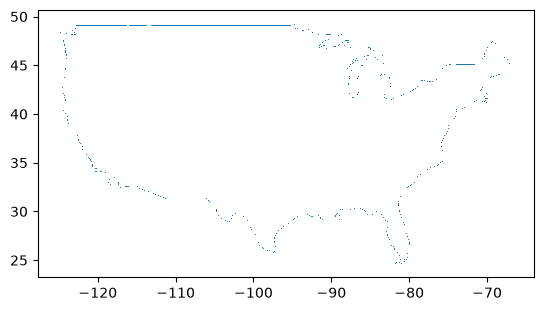

In [271]:
C[C.lon_x.isna()].set_geometry("geometry_y").plot()

In [265]:
iou = cells.intersection(cells2).area / cells.union(cells2).area
(iou > 0.999).all()

/var/folders/2r/78dg63lx1vg81rz95pp5vkj00000gp/T/ipykernel_74049/3362433000.py:1: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  iou = cells.intersection(cells2).area / cells.union(cells2).area
/var/folders/2r/78dg63lx1vg81rz95pp5vkj00000gp/T/ipykernel_74049/3362433000.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  iou = cells.intersection(cells2).area / cells.union(cells2).area


np.False_

,col,row,lon,lat,geometry
0,717,12,-95.125000,49.416667,"POLYGON ((-95.14583 49.4375, -95.10417 49.4375..."
1,716,13,-95.166667,49.375000,"POLYGON ((-95.1875 49.39583, -95.14583 49.3958..."
2,717,13,-95.125000,49.375000,"POLYGON ((-95.14583 49.39583, -95.10417 49.395..."
3,718,13,-95.083333,49.375000,"POLYGON ((-95.10417 49.39583, -95.0625 49.3958..."
4,719,13,-95.041667,49.375000,"POLYGON ((-95.0625 49.39583, -95.02083 49.3958..."
...,...,...,...,...,...
481626,1040,609,-81.666667,24.541667,"POLYGON ((-81.6875 24.5625, -81.64583 24.5625,..."
481627,1041,609,-81.625000,24.541667,"POLYGON ((-81.64583 24.5625, -81.60417 24.5625..."
481628,1028,610,-82.166667,24.500000,"POLYGON ((-82.1875 24.52083, -82.14583 24.5208..."
481629,1029,610,-82.125000,24.500000,"POLYGON ((-82.14583 24.52083, -82.10417 24.520..."
